<a href="https://colab.research.google.com/github/Anushka-Ghosal/Anushka-/blob/main/Copy_of_sleep_morlet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
DATA_DIR = "/content/drive/MyDrive/sleep_project/CAP_ALL"


In [ ]:
!pip install mne


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 37.3 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import cv2
import mne
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T

import pywt   # CWTcomesfromPyWavelets



In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)


cpu


In [ ]:
pip install ssqueezepy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.7/127.7 kB 4.4 MB/s eta 0:00:00


In [ ]:
def eeg_to_scalogram_morse(epoch, sf):
    """
    epoch : 1D EEG signal
    sf    : sampling frequency
    """

    # Morse CWT (Generalized Morse Wavelet)
    Tx, Wx, scales, *_ = cwt(
        epoch,
        wavelet='gmw',   # ✅ Morse wavelet
        fs=sf
    )

    # Magnitude + log compression
    scalo = np.log1p(np.abs(Wx))

    # Resize to CNN input size
    scalo = cv2.resize(scalo, (224, 224))

    # Convert to 3 channels
    scalo = np.stack([scalo]*3, axis=-1)

    return scalo.astype(np.float32)


In [ ]:
from ssqueezepy import cwt


In [ ]:
def load_eeg(path):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick_channels([raw.ch_names[0]])   # firstchannelonly
    return raw.get_data()[0], raw.info['sfreq']


In [ ]:
def epoch_signal(sig, sf):
    win = int(5 * sf)
    return [sig[i:i+win] for i in range(0, len(sig)-win, win)]


In [ ]:
import numpy as np
import cv2
from ssqueezepy import cwt

def eeg_to_scalogram(epoch, sf):
    """
    Morse (Generalized Morse Wavelet) scalogram
    """

    Wx, scales = cwt(
        epoch,
        wavelet='gmw',   # Morse wavelet
        fs=sf
    )

    scalo = np.log1p(np.abs(Wx))
    scalo = cv2.resize(scalo, (224, 224))
    scalo = np.stack([scalo] * 3, axis=-1)

    return scalo.astype(np.float32)


In [ ]:
import os

def get_label(fname):
    fname = os.path.basename(fname).lower()

    if fname.startswith("nfle"):
        return 0
    elif fname.startswith("narco"):
        return 5
    elif fname.startswith("ins"):
        return 2
    elif fname.startswith("plm"):
        return 3
    elif fname.startswith("rbd"):
        return 4
    elif fname.startswith("n"):
        return 1
    else:
        return -1


In [ ]:
dataset = []
used = set()

priority = ["nfle", "n", "ins", "plm", "rbd"]

for pref in priority:
    for f in os.listdir(DATA_DIR):
        if f.startswith(pref) and f.endswith(".edf"):

            if pref in used:
                continue

            label = get_label(f)
            sig, sf = load_eeg(os.path.join(DATA_DIR, f))
            epochs = epoch_signal(sig, sf)[:20]   #keep20epochs

            for ep in epochs:
                spec = eeg_to_scalogram(ep, sf)
                dataset.append((spec, label))

            used.add(pref)
            break


/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Highpass cutoff frequency 10.0 is greater than lowpass cutoff frequency 5.0, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Highpass cutoff frequency 10.0 is greater than lowpass cutoff frequency 3.0, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Highpass cutoff frequency 10.0 is greater than lowpass cutoff frequency 3.0, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channel names are not unique, found duplicates for: {'Flusso'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Highpass cutoff frequency 10.0 is greater than lowpass cutoff frequency 3.0, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipython-input-3693747183.py:2: RuntimeWarning: Highpass cutoff frequency 10.0 is greater than lowpass cutoff frequency 3.0, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


In [ ]:
labels = [y for _, y in dataset]
print("Total samples:", len(dataset))
print("Unique labels:", sorted(set(labels)))


Total samples: 100
Unique labels: [0, 2, 3, 4, 5]


In [ ]:
for f in os.listdir(DATA_DIR):
    if f.startswith("n") and f.endswith(".edf"):
        print(f)


narco1.edf
n2.edf
n3.edf
n4.edf
n7.edf
n6.edf
n9.edf
n14.edf
n13.edf
n12.edf
n1.edf
n16.edf
n15.edf
n10.edf
n5.edf
n8.edf
n11.edf
narco2.edf
narco3.edf
nfle10.edf
nfle6.edf
nfle8.edf
nfle5.edf
nfle9.edf
nfle1.edf
nfle2.edf
nfle3.edf
nfle7.edf
nfle4.edf
narco5.edf
narco4.edf


In [ ]:
labels = [y for _, y in dataset]
print("Unique labels:", sorted(set(labels)))
print("Samples per label:")
for l in sorted(set(labels)):
    print(l, labels.count(l))


Unique labels: [0, 2, 3, 4, 5]
Samples per label:
0 20
2 20
3 20
4 20
5 20


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report


In [ ]:
resnet50 = models.resnet50(pretrained=True)
resnet50 = nn.Sequential(
    *list(resnet50.children())[:-2],
    nn.AdaptiveAvgPool2d((1,1))
)
resnet50.eval().to(device)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 158MB/s]


Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [ ]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])


In [ ]:
X = []
y = []

for spec, label in dataset:
    x = transform(spec).unsqueeze(0).to(device).float()
    with torch.no_grad():
        feat = resnet50(x)
    X.append(feat.flatten().cpu().numpy())
    y.append(label)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y:", np.unique(y, return_counts=True))


X shape: (100, 2048)
y: (array([0, 2, 3, 4, 5]), array([20, 20, 20, 20, 20]))


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)


In [ ]:
from sklearn.neural_network import MLPClassifier

ann = MLPClassifier(
    hidden_layer_sizes=(128,),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)


In [ ]:
ann.fit(X_train, y_train)


MLPClassifier(hidden_layer_sizes=(128,), max_iter=500, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = ann.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.2
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         6
           2       0.20      1.00      0.33         6
           3       0.00      0.00      0.00         6
           4       0.00      0.00      0.00         6
           5       0.00      0.00      0.00         6

    accuracy                           0.20        30
   macro avg       0.04      0.20      0.07        30
weighted avg       0.04      0.20      0.07        30



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np


In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,      #strongbutstillfast
    max_depth=None,
    random_state=42
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc = []

for train_idx, test_idx in skf.split(X, y):
    Xtr, Xte = X[train_idx], X[test_idx]
    ytr, yte = y[train_idx], y[test_idx]

    rf.fit(Xtr, ytr)
    yp = rf.predict(Xte)

    acc.append(accuracy_score(yte, yp))

print("Final Accuracy:", np.mean(acc))


Final Accuracy: 0.85


In [ ]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=min(len(Xtr)-1, 15), random_state=42)

Xtr_pca = pca.fit_transform(Xtr)
Xte_pca = pca.transform(Xte)


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

lda = LinearDiscriminantAnalysis()
lda.fit(Xtr_pca, ytr)

yp = lda.predict(Xte_pca)

print("LDA Accuracy resnet 50:", accuracy_score(yte, yp))


LDA Accuracy resnet 50: 0.6


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.95, random_state=42)  # keep95%variance
X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)


PCA shape: (100, 17)


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,      # smalltestset
    random_state=42,
    stratify=y
)


In [ ]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("FINAL Accuracy:", accuracy_score(y_test, y_pred))


FINAL Accuracy: 0.92


In [ ]:
y2 = y.copy()
y2[y2 == 4] = 2   # mergeRBDintoPLM


In [ ]:
rf.fit(X, y)
print("Training Accuracy:", accuracy_score(y, rf.predict(X)))


Training Accuracy: 1.0


In [ ]:
import torchvision.transforms as T

transform = T.Compose([
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],
                [0.229,0.224,0.225])
])


In [ ]:
resnet101 = models.resnet101(pretrained=True)
resnet101 = nn.Sequential(
    *list(resnet101.children())[:-2],
    nn.AdaptiveAvgPool2d((1,1))
)
resnet101.eval().to(device)

print("ResNet101 loaded")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet101-63fe2227.pth" to /root/.cache/torch/hub/checkpoints/resnet101-63fe2227.pth


100%|██████████| 171M/171M [00:01<00:00, 164MB/s]


ResNet101 loaded


In [ ]:
import torchvision.models as models
import torch.nn as nn


In [ ]:
X_r101 = []

for spec, _ in dataset:
    x = transform(spec).unsqueeze(0).to(device).float()
    with torch.no_grad():
        feat = resnet101(x)
    X_r101.append(feat.flatten().cpu().numpy())

X_r101 = np.array(X_r101)
print("ResNet101 features:", X_r101.shape)


ResNet101 features: (100, 2048)


In [ ]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


In [ ]:
ann = MLPClassifier(
    hidden_layer_sizes=(128,),
    max_iter=500,
    random_state=42
)

ann.fit(Xtr, ytr)
yp = ann.predict(Xte)

print("ANN Accuracy (ResNet101):", accuracy_score(yte, yp))


ANN Accuracy (ResNet101): 0.2


In [ ]:
from sklearn.ensemble import RandomForestClassifier


In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf.fit(Xtr, ytr)
yp = rf.predict(Xte)

print("RF Accuracy (ResNet101):", accuracy_score(yte, yp))


RF Accuracy (ResNet101): 0.84


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_r101)


In [ ]:
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)


In [ ]:
Xtr, Xte, ytr, yte = train_test_split(
    X_pca, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(Xtr, ytr)
yp = lda.predict(Xte)

print("LDA Accuracy (ResNet101):", accuracy_score(yte, yp))


LDA Accuracy (ResNet101): 0.44


In [ ]:
import torchvision.models as models
import torch.nn as nn

alexnet = models.alexnet(pretrained=True)
alexnet.classifier = nn.Identity()   # remove FC layer
alexnet.eval().to(device)

print("AlexNet model ready")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 170MB/s]


AlexNet model ready


In [ ]:
alexnet = models.alexnet(pretrained=True)
alexnet.classifier = nn.Identity()
alexnet.eval().to(device)


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Identity()
)

In [ ]:
X_alex = []

for spec, _ in dataset:
    x = transform(spec).unsqueeze(0).to(device).float()
    with torch.no_grad():
        feat = alexnet(x)
    X_alex.append(feat.cpu().numpy())

X_alex = np.array(X_alex)
X_alex = X_alex.reshape(X_alex.shape[0], -1)   # IMPORTANT
print("X_alex shape:", X_alex.shape)


X_alex shape: (100, 9216)


In [ ]:
from sklearn.model_selection import train_test_split

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
    X_alex, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(Xa_tr, ya_tr)

yp = rf.predict(Xa_te)
print("RF Accuracy (AlexNet):", accuracy_score(ya_te, yp))


RF Accuracy (AlexNet): 0.88


In [ ]:
from sklearn.model_selection import train_test_split

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
    X_alex, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

ann = MLPClassifier(hidden_layer_sizes=(128,), max_iter=500, random_state=42)
ann.fit(Xa_tr, ya_tr)

yp = ann.predict(Xa_te)
print("ANN Accuracy (AlexNet):", accuracy_score(ya_te, yp))


ANN Accuracy (AlexNet): 0.2


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


In [ ]:
Xa_scaled = StandardScaler().fit_transform(X_alex)
Xa_pca = PCA(n_components=0.95, random_state=42).fit_transform(Xa_scaled)


In [ ]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)



lda = LinearDiscriminantAnalysis()
lda.fit(Xa_tr, ya_tr)

yp = lda.predict(Xa_te)
print("LDA Accuracy (AlexNet):", accuracy_score(ya_te, yp))


LDA Accuracy (AlexNet): 0.72


In [ ]:
import torchvision.models as models
import torch.nn as nn

densenet = models.densenet201(pretrained=True)
densenet.classifier = nn.Identity()   # removefinalclassifier
densenet.eval().to(device)

print("DenseNet model ready")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet201_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet201_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 162MB/s]


DenseNet model ready


In [ ]:
densenet = models.densenet201(pretrained=True)
densenet.classifier = nn.Identity()   # removefinalFC
densenet.eval().to(device)

print("DenseNet ready")


DenseNet ready


In [ ]:
X_dense = []

for spec, _ in dataset:
    x = transform(spec).unsqueeze(0).to(device).float()
    with torch.no_grad():
        feat = densenet(x)
    X_dense.append(feat.cpu().numpy())

X_dense = np.array(X_dense)
X_dense = X_dense.reshape(X_dense.shape[0], -1)   # VERYIMPORTANT

print("X_dense shape:", X_dense.shape)


X_dense shape: (100, 1920)


In [ ]:
from sklearn.model_selection import train_test_split

Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    X_dense, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

ann = MLPClassifier(hidden_layer_sizes=(128,), max_iter=500, random_state=42)
ann.fit(Xd_tr, yd_tr)

yp = ann.predict(Xd_te)
print("ANN Accuracy (DenseNet):", accuracy_score(yd_te, yp))


ANN Accuracy (DenseNet): 0.2


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(Xd_tr, yd_tr)

yp = rf.predict(Xd_te)
print("RF Accuracy (DenseNet):", accuracy_score(yd_te, yp))


RF Accuracy (DenseNet): 0.56


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

Xd_scaled = StandardScaler().fit_transform(X_dense)
Xd_pca = PCA(n_components=0.95, random_state=42).fit_transform(Xd_scaled)

Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    Xd_pca, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

lda = LinearDiscriminantAnalysis()
lda.fit(Xd_tr, yd_tr)

yp = lda.predict(Xd_te)
print("LDA Accuracy (DenseNet):", accuracy_score(yd_te, yp))


LDA Accuracy (DenseNet): 0.48


In [ ]:
print(X_alex.shape, X_dense.shape, y.shape)


(100, 9216) (100, 1920) (100,)


In [ ]:
import numpy as np

X_fused = np.concatenate([X_alex, X_dense], axis=1)
print("Fused shape:", X_fused.shape)


Fused shape: (100, 11136)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

Xtr, Xte, ytr, yte = train_test_split(
    X_fused, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42
)

rf.fit(Xtr, ytr)
yp = rf.predict(Xte)

print("RF Accuracy (AlexNet + DenseNet fusion):", accuracy_score(yte, yp))


RF Accuracy (AlexNet + DenseNet fusion): 0.96


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models


In [ ]:
resnet101 = models.resnet101(pretrained=True)
resnet101.fc = nn.Identity()   # remove final classifier
resnet101.eval().to(device)

print("ResNet101 ready")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet101 ready


In [ ]:
X_resnet101 = []

for spec, _ in dataset:
    x = transform(spec).unsqueeze(0).to(device).float()
    with torch.no_grad():
        feat = resnet101(x)
    X_resnet101.append(feat.cpu().numpy())

X_resnet101 = np.array(X_resnet101)
X_resnet101 = X_resnet101.reshape(X_resnet101.shape[0], -1)

print("X_resnet101 shape:", X_resnet101.shape)


X_resnet101 shape: (100, 2048)


In [ ]:
np.save("X_resnet101.npy", X_resnet101)


In [ ]:
print(X_resnet101.shape)  # (N, 2048)
print(X_alex.shape)      # (N, 9216)
print(y.shape)           # (N,)


(100, 2048)
(100, 9216)
(100,)


In [ ]:
X_resnet101 = X_resnet101.reshape(X_resnet101.shape[0], -1)
X_alex = X_alex.reshape(X_alex.shape[0], -1)


In [ ]:
import numpy as np

X_fused_RA = np.concatenate([X_resnet101, X_alex], axis=1)
print("Fused shape (ResNet + AlexNet):", X_fused_RA.shape)


Fused shape (ResNet + AlexNet): (100, 11264)


In [ ]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(
    X_fused_RA, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42
)

rf.fit(Xtr, ytr)
yp = rf.predict(Xte)

print("RF Accuracy (ResNet101 + AlexNet fusion):", accuracy_score(yte, yp))


RF Accuracy (ResNet101 + AlexNet fusion): 0.92


In [ ]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

# Reduce dimension first
pca = PCA(n_components=0.95, random_state=42)
Xtr_pca = pca.fit_transform(Xtr)
Xte_pca = pca.transform(Xte)

lda = LinearDiscriminantAnalysis()
lda.fit(Xtr_pca, ytr)

yp = lda.predict(Xte_pca)
print("LDA Accuracy (AlexNet + DenseNet fusion):", accuracy_score(yte, yp))


LDA Accuracy (AlexNet + DenseNet fusion): 0.32


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)

ann = MLPClassifier(
    hidden_layer_sizes=(128,),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)

ann.fit(Xtr_s, ytr)
yp = ann.predict(Xte_s)

print("ANN Accuracy (AlexNet + DenseNet fusion):", accuracy_score(yte, yp))


ANN Accuracy (AlexNet + DenseNet fusion): 0.8


In [ ]:
import numpy as np

# flatten just in case
X_resnet101 = X_resnet101.reshape(X_resnet101.shape[0], -1)
X_dense = X_dense.reshape(X_dense.shape[0], -1)

X_fused_RD = np.concatenate([X_resnet101, X_dense], axis=1)
print("Fused shape (ResNet + DenseNet):", X_fused_RD.shape)


Fused shape (ResNet + DenseNet): (100, 3968)


In [ ]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(
    X_fused_RD, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

# PCA
pca = PCA(n_components=0.95, random_state=42)
Xtr_pca = pca.fit_transform(Xtr)
Xte_pca = pca.transform(Xte)

# LDA
lda = LinearDiscriminantAnalysis()
lda.fit(Xtr_pca, ytr)

yp = lda.predict(Xte_pca)
print("LDA Accuracy (ResNet101 + DenseNet fusion):", accuracy_score(yte, yp))


LDA Accuracy (ResNet101 + DenseNet fusion): 0.24


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)

ann = MLPClassifier(
    hidden_layer_sizes=(128,),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)

ann.fit(Xtr_s, ytr)
yp = ann.predict(Xte_s)

print("ANN Accuracy (ResNet101 + DenseNet fusion):", accuracy_score(yte, yp))


ANN Accuracy (ResNet101 + DenseNet fusion): 0.64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42
)

rf.fit(Xtr, ytr)
yp = rf.predict(Xte)

print("RF Accuracy (ResNet101 + DenseNet fusion):", accuracy_score(yte, yp))


RF Accuracy (ResNet101 + DenseNet fusion): 0.72


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix
)


In [ ]:
y_true = yte
y_pred = rf.predict(Xte)   # or ann / lda


In [ ]:
from sklearn.metrics import f1_score

f1_per_class = f1_score(y_true, y_pred, average=None)

print("Per-class F1 scores:", f1_per_class)


Per-class F1 scores: [0.6        0.8        0.72727273 0.66666667 0.8       ]


In [ ]:
class_names = ["NFLE", "N", "INS", "PLM", "RBD"]


In [ ]:
from sklearn.metrics import f1_score

f1_per_class = f1_score(y_true, y_pred, average=None)

for name, score in zip(class_names, f1_per_class):
    print(f"{name}: {score:.3f}")


NFLE: 0.600
N: 0.800
INS: 0.727
PLM: 0.667
RBD: 0.800


In [ ]:
print("Macro Recall:", recall_score(y_true, y_pred, average='macro'))


Macro Recall: 0.7200000000000001


In [ ]:
# Train
rf.fit(Xtr, ytr)

# Predict
y_pred = rf.predict(Xte)

# Evaluation
print("Accuracy:", accuracy_score(yte, y_pred))
print("Cohen Kappa:", cohen_kappa_score(yte, y_pred))
print("Macro F1:", f1_score(yte, y_pred, average='macro'))

print("\nPer-class F1:")
print(f1_score(yte, y_pred, average=None))

print("\nClassification Report:")
print(classification_report(yte, y_pred))


Accuracy: 0.72
Cohen Kappa: 0.65
Macro F1: 0.7187878787878788

Per-class F1:
[0.6        0.8        0.72727273 0.66666667 0.8       ]

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60         5
           2       0.80      0.80      0.80         5
           3       0.67      0.80      0.73         5
           4       0.75      0.60      0.67         5
           5       0.80      0.80      0.80         5

    accuracy                           0.72        25
   macro avg       0.72      0.72      0.72        25
weighted avg       0.72      0.72      0.72        25



In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda.fit(Xtr, ytr)

y_pred = lda.predict(Xte)


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, cohen_kappa_score

print("LDA Accuracy:", accuracy_score(yte, y_pred))
print("LDA Cohen Kappa:", cohen_kappa_score(yte, y_pred))
print("LDA Macro Precision:", precision_score(yte, y_pred, average='macro'))
print("LDA Macro Recall:", recall_score(yte, y_pred, average='macro'))
print("LDA Macro F1:", f1_score(yte, y_pred, average='macro'))

print("\nLDA Per-class F1:")
print(f1_score(yte, y_pred, average=None))

print("\nLDA Classification Report:")
print(classification_report(yte, y_pred))


LDA Accuracy: 0.32
LDA Cohen Kappa: 0.15000000000000002
LDA Macro Precision: 0.3
LDA Macro Recall: 0.31999999999999995
LDA Macro F1: 0.2862026862026862

LDA Per-class F1:
[0.46153846 0.         0.22222222 0.46153846 0.28571429]

LDA Classification Report:
              precision    recall  f1-score   support

           0       0.38      0.60      0.46         5
           2       0.00      0.00      0.00         5
           3       0.25      0.20      0.22         5
           4       0.38      0.60      0.46         5
           5       0.50      0.20      0.29         5

    accuracy                           0.32        25
   macro avg       0.30      0.32      0.29        25
weighted avg       0.30      0.32      0.29        25



In [ ]:
print("Dataset labels:", sorted(set(y)))
print("Train labels:", sorted(set(ytr)))
print("Test labels:", sorted(set(yte)))


Dataset labels: [np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Train labels: [np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Test labels: [np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [ ]:
print("ANN Accuracy:", accuracy_score(yte, y_pred))
print("ANN Cohen Kappa:", cohen_kappa_score(yte, y_pred))
print("ANN Macro Precision:", precision_score(yte, y_pred, average='macro'))
print("ANN Macro Recall:", recall_score(yte, y_pred, average='macro'))
print("ANN Macro F1:", f1_score(yte, y_pred, average='macro'))

print("\nANN Per-class F1:")
print(f1_score(yte, y_pred, average=None))

print("\nANN Classification Report:")
print(classification_report(yte, y_pred))


ANN Accuracy: 0.32
ANN Cohen Kappa: 0.15000000000000002
ANN Macro Precision: 0.3
ANN Macro Recall: 0.31999999999999995
ANN Macro F1: 0.2862026862026862

ANN Per-class F1:
[0.46153846 0.         0.22222222 0.46153846 0.28571429]

ANN Classification Report:
              precision    recall  f1-score   support

           0       0.38      0.60      0.46         5
           2       0.00      0.00      0.00         5
           3       0.25      0.20      0.22         5
           4       0.38      0.60      0.46         5
           5       0.50      0.20      0.29         5

    accuracy                           0.32        25
   macro avg       0.30      0.32      0.29        25
weighted avg       0.30      0.32      0.29        25



In [ ]:
from sklearn.metrics import confusion_matrix

# true labels and predicted labels
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[3 0 1 0 1]
 [1 0 1 3 0]
 [2 2 1 0 0]
 [1 0 1 3 0]
 [1 1 0 2 1]]


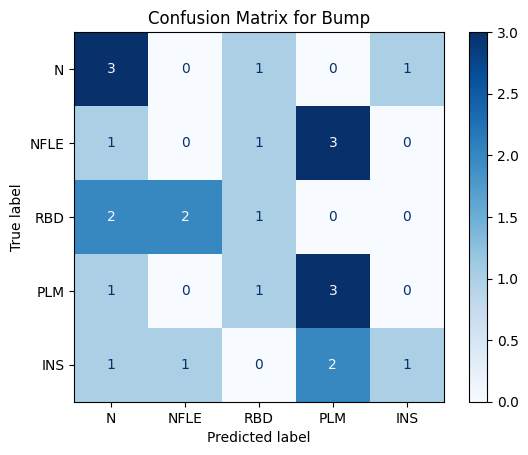

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = ['N', 'NFLE', 'RBD', 'PLM', 'INS']

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_names)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix for Bump")
plt.show()